In [1]:
# Backpropagation Algorithm - built from scratch with plain NumPy
# Dataset: XOR - the classic example, made up by hand (no download needed)
#
# WHY XOR? It's the smallest problem that a single-layer network (no hidden
# layer) genuinely CANNOT solve - the data isn't linearly separable. That's
# historically why hidden layers + backpropagation became necessary at all.
#
# XOR truth table:
#   Input A | Input B | Output
#      0    |    0    |   0
#      0    |    1    |   1
#      1    |    0    |   1
#      1    |    1    |   0

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ---- 1. The data ----
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])
y = np.array([[0], [1], [1], [0]])   # column vector

# ---- 2. Network architecture ----
# 2 input neurons -> 4 hidden neurons -> 1 output neuron
n_input = 2
n_hidden = 4
n_output = 1

# ---- 3. Initialize weights and biases randomly ----
# small random values - starting at exactly 0 would make every hidden neuron
# learn the identical thing (no point having multiple neurons then)
W1 = np.random.randn(n_input, n_hidden) * 0.5    # weights: input -> hidden
b1 = np.zeros((1, n_hidden))                     # bias for hidden layer
W2 = np.random.randn(n_hidden, n_output) * 0.5   # weights: hidden -> output
b2 = np.zeros((1, n_output))                     # bias for output layer


In [3]:
# ---- 4. Activation function (sigmoid) and its derivative ----
# sigmoid squashes any number into (0, 1) - useful for a 0/1 style output
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    # derivative of sigmoid, expressed in terms of its OWN output "a"
    # (a neat shortcut: if a = sigmoid(z), then sigmoid'(z) = a * (1 - a))
    return a * (1 - a)

learning_rate = 0.5
epochs = 10000
loss_history = []


In [4]:
# ---- 5. Training loop: forward pass -> compute loss -> backward pass -> update ----
for epoch in range(epochs):

    # ---- FORWARD PASS ----
    # hidden layer: weighted sum, then activation
    z1 = X @ W1 + b1
    a1 = sigmoid(z1)

    # output layer: weighted sum, then activation
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)          # this is the network's prediction

    # ---- LOSS ----
    # mean squared error between prediction and actual
    loss = np.mean((y - a2) ** 2)
    loss_history.append(loss)

    # ---- BACKWARD PASS (this IS backpropagation) ----
    # the whole idea: figure out how much each weight contributed to the
    # error, by working BACKWARDS from the output error through the chain rule

    # step 1: how wrong was the output, and how sensitive is it to its input?
    error_output = y - a2                          # how far off we are
    delta_output = error_output * sigmoid_derivative(a2)   # error scaled by activation slope

    # step 2: push that error backwards into the hidden layer
    error_hidden = delta_output @ W2.T              # spread blame back through W2
    delta_hidden = error_hidden * sigmoid_derivative(a1)   # scaled by hidden activation slope
    
    # step 3: use these deltas to compute how much each weight should change
    # (gradient = how the layer's input relates to the error signal at that layer)
    W2_gradient = a1.T @ delta_output
    b2_gradient = np.sum(delta_output, axis=0, keepdims=True)

    W1_gradient = X.T @ delta_hidden
    b1_gradient = np.sum(delta_hidden, axis=0, keepdims=True)

    # ---- UPDATE WEIGHTS ----
    # move weights in the direction that REDUCES the error
    # (gradient ASCENT would increase it - we use + here because we defined
    #  error_output = y - a2, the opposite sign convention to the more common
    #  "loss gradient descent"; either works, just stay consistent)
    W2 += learning_rate * W2_gradient
    b2 += learning_rate * b2_gradient
    W1 += learning_rate * W1_gradient
    b1 += learning_rate * b1_gradient

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:5d}  Loss: {loss:.5f}")


Epoch     0  Loss: 0.25568
Epoch  1000  Loss: 0.20331
Epoch  2000  Loss: 0.00521
Epoch  3000  Loss: 0.00174
Epoch  4000  Loss: 0.00100
Epoch  5000  Loss: 0.00070
Epoch  6000  Loss: 0.00053
Epoch  7000  Loss: 0.00043
Epoch  8000  Loss: 0.00035
Epoch  9000  Loss: 0.00030


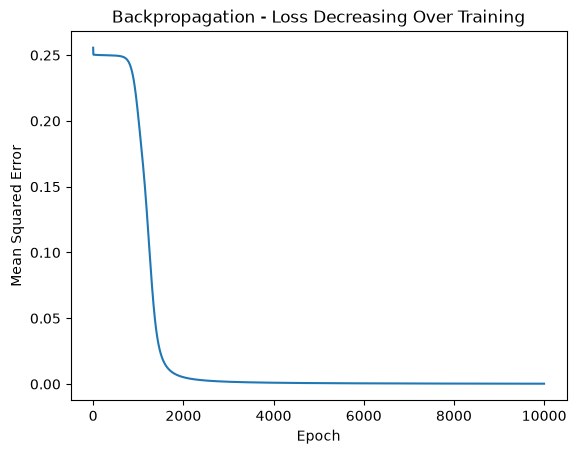


Final predictions after training:
Input: [0 0]  ->  Predicted: 0.0187  (rounded: 0)  Actual: 0
Input: [0 1]  ->  Predicted: 0.9845  (rounded: 1)  Actual: 1
Input: [1 0]  ->  Predicted: 0.9844  (rounded: 1)  Actual: 1
Input: [1 1]  ->  Predicted: 0.0151  (rounded: 0)  Actual: 0

sklearn MLPClassifier predictions:
[0 1 1 0]
Actual:          [0 1 1 0]


In [5]:
# ---- 6. Plot how loss decreased over training ----
plt.plot(loss_history)
plt.title("Backpropagation - Loss Decreasing Over Training")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.show()

# ---- 7. Final predictions ----
print("\nFinal predictions after training:")
z1 = X @ W1 + b1
a1 = sigmoid(z1)
z2 = a1 @ W2 + b2
a2 = sigmoid(z2)

for i in range(len(X)):
    print(f"Input: {X[i]}  ->  Predicted: {a2[i][0]:.4f}  (rounded: {round(a2[i][0])})  Actual: {y[i][0]}")

# the network should now correctly predict all 4 XOR cases - something a
# single-layer (no hidden layer) network is mathematically incapable of doing


# ============================================================
# BONUS - same exact problem, solved with sklearn's MLPClassifier
# (so you can see "from scratch" vs "library" produce the same result)
# ============================================================
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(8,), activation="relu",
                     solver="adam", max_iter=5000, random_state=42)
mlp.fit(X, y.ravel())

print("\nsklearn MLPClassifier predictions:")
print(mlp.predict(X))
print("Actual:         ", y.ravel())